In [16]:
def extract_time(filename):
    import re
    match = re.search(r'(\d{2}):(\d{2})', filename)
    if match:
        time=int(match.group(1))*60+ int(match.group(2))
        #print(time,int(match.group(1)), int(match.group(2)))
        #return time  # (hh, mm)
        return int(match.group(1)), int(match.group(2))  # (hh, mm)
    return (99,99)  # Un valore alto per file senza orario

def make_animation(gif_filepath):
    from PIL import Image
    import os
    from IPython.display import Image as IPImage
    from IPython.display import display
    import time
    
    image_folder = '/glade/u/home/fdemartin/plot/anim/files/' # répertoire contenant les fichiers PNG
    output_file = gif_filepath # nom du fichier de sortie
    animation_speed = 0.9 # vitesse de l'animation en secondes
    
    # Liste tous les fichiers PNG dans le répertoire image_folder
    #files = sorted(os.listdir(image_folder))
    files = os.listdir(image_folder)
    # Ordinare la lista in base all'orario estratto
    #sorted_files = sorted(files, key=extract_time)
    files = [f for f in files if extract_time(f)[0] >= 16]
    files = sorted(files, key=extract_time)
    print(files)
    image_files = [f for f in files if f.endswith('.png')]
    
    # Ouvre chaque fichier PNG et ajoute l'image à une liste
    images = []
    for filename in image_files:
        img = Image.open(os.path.join(image_folder, filename))
        images.append(img)
    
    # Crée l'animation GIF
    images[0].save(output_file, save_all=True, append_images=images[1:], duration=int(animation_speed*1000), loop=0)
    # Affiche l'animation GIF dans Jupyter
    with open(output_file,'rb') as f:
        display(IPImage(data=f.read(), format='png'))
    # Efface les fichiers PNG
    for filename in image_files:
        os.remove(image_folder+filename)

In [17]:
import metpy.calc as mpcalc
from metpy.cbook import get_test_data
import matplotlib.pyplot as plt
#from metpy.plots import Hodograph, SkewT
from metpy.units import units
import numpy as np
import csv
import os
from netCDF4 import Dataset
import xarray as xr
from wrf import (getvar, interplevel, vertcross, 
                 CoordPair, ALL_TIMES, to_np,ll_to_xy,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times)
from matplotlib.ticker import FormatStrFormatter

In [18]:
exp='10km'
member='4'
WRF_DIRECTORY="/glade/derecho/scratch/fdemartin/ens/"+exp+"/"+member+"/"

#WRF_DIRECTORY=dir+"1_wrfout_d01_2023-05-31_08:00:00"
os.chdir(WRF_DIRECTORY)
WRF_FILES = os.listdir()

_WRF_FILES = [os.path.abspath(os.path.expanduser(
    os.path.join(WRF_DIRECTORY, f))) for f in WRF_FILES]

def single_wrf_file():
    global _WRF_FILES
    return _WRF_FILES[0]

def multiple_wrf_files():
    global _WRF_FILES
    return _WRF_FILES

file_paths = multiple_wrf_files() # Necessary due to single_wrf_file being a function
#print(file_paths)
file_paths = sorted(file_paths, key=extract_time)

wrf_files = [Dataset(f) for f in file_paths]
period=len(WRF_FILES)

#ncfile = Dataset(WRF_DIRECTORY)
times = to_np(getvar(wrf_files,'times',timeidx=ALL_TIMES, meta=False,method="cat"))
# print(times)
#time_wrf1=np.linspace(start_time,start_time+delta_time*(period-1),period)*units.hour

#p_join = getvar(wrflist, "P", timeidx=ALL_TIMES, method="join")
print('ok')
var=to_np(getvar(wrf_files,"mdbz",timeidx=ALL_TIMES,method="cat"))
print('ok')
uh=to_np(getvar(wrf_files,"UP_HELI_MAX",timeidx=ALL_TIMES,method="cat"))
#wa=to_np(getvar(wrf_files,"wa",timeidx=ALL_TIMES,method="cat"))
#p=to_np(getvar(wrf_files,"pressure",timeidx=ALL_TIMES,method="cat"))

var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))
#w950 = interplevel(wa, p, 950)
#df=pd.DataFrame(np.transpose([var,uh,times]),index=times, columns=['mdbz','uh','times'])
#df = pd.DataFrame({'times': pd.to_datetime(times)})
#df_sorted = df.sort_values('times')
#levels_dbz=np.arange(20,60,8)
#cape = to_np(getvar(wrf_files, 'cape2d',timeidx=ALL_TIMES,method="cat"))[0]

# exp="no_urban"
# WRF_DIRECTORY="/glade/derecho/scratch/fdemartin/ens/"+exp+"/"+member+"/"
# os.chdir(WRF_DIRECTORY)
# WRF_FILES = os.listdir()

# _WRF_FILES = [os.path.abspath(os.path.expanduser(
#     os.path.join(WRF_DIRECTORY, f))) for f in WRF_FILES]

# file_paths = multiple_wrf_files() # Necessary due to single_wrf_file being a function
# #print(file_paths)
# file_paths = sorted(file_paths, key=extract_time)
# wrf_files = [Dataset(f) for f in file_paths]
# cape_nu = to_np(getvar(wrf_files, 'cape2d',timeidx=ALL_TIMES,method="cat"))[0]
# # times = to_np(getvar(wrf_files,'times',timeidx=ALL_TIMES, meta=False,method="cat"))
# # print(times)
# cape=cape-cape_nu

ok
ok


['dbz_16:00.png', 'dbz_16:10.png', 'dbz_16:20.png', 'dbz_16:30.png', 'dbz_16:40.png', 'dbz_16:50.png', 'dbz_17:00.png', 'dbz_17:10.png', 'dbz_17:20.png', 'dbz_17:30.png', 'dbz_17:40.png', 'dbz_17:50.png', 'dbz_18:00.png', 'dbz_18:10.png', 'dbz_18:20.png', 'dbz_18:30.png', 'dbz_18:40.png', 'dbz_18:50.png', 'dbz_19:00.png', 'dbz_19:10.png', 'dbz_19:20.png', 'dbz_19:30.png', 'dbz_19:40.png', 'dbz_19:50.png', 'dbz_20:00.png']


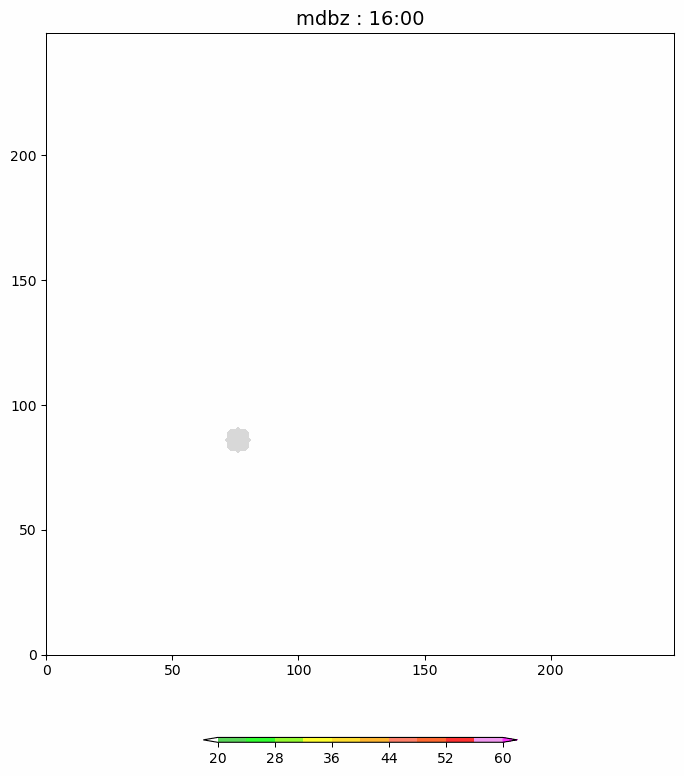

In [19]:
levels_cape=np.arange(-200,200,10)
#print(levels_cape)
#print(cape)
#times = to_np(getvar(wrf_files, 'times',timeidx=ALL_TIMES,method="cat"))
#print(times, times+2)
#print(times)
x=np.arange(0,250,1)
y=np.arange(0,250,1)
#print(np.shape(cape))
levels=np.linspace(20,60,num=11)
#levels=np.linspace(0,45,num=13)
color=['white','limegreen','lime','lawngreen','yellow','gold','orange','tomato','orangered','red','violet','magenta']
#print(times[0])
#print(str(times[0])[11:13]+str(times[0])[13:16])
#print(str(int(str(times[0])[11:13])+2)+str(times[0])[13:16])

for i in range(0,np.shape(times)[0]):
    #hour=14
    # date=str(times)[i][0:-19]
    # time1=str(times)[i][0:-13]
    # time=str(time1.split('T')[1])
    # hour=str(time.split(':')[0])
    # minute=str(time.split(':')[1])
    
    fig = plt.figure(figsize=(8.1, 10.76))
    #print(str(times[i,0])[11:16])
    ax = fig.add_subplot(1, 1, 1)
    ax.set_title('mdbz : '+str(int(str(times[i])[11:13])+2)+str(times[i])[13:16],loc='center',fontsize=14)
    #ax.set_ylim(0,200)
    # MSLP in contours and min max
    #c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
    #ax.clabel(c1,fmt='%4.1i',fontsize=10)
    #cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
    #capez = ax.contourf(x, y, to_np(cape[i,:,:]), cmap='seismic', levels=levels_cape, extend='both')
    cf = ax.contourf(x, y, to_np(var[i,:,:]), levels=levels, colors=color, extend='both',alpha=0.8)
    gz = ax.contourf(x, y, to_np(var_lu[i,:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
    #az = ax.contour(x, y, to_np(w950[i,:,:]), levels=[0.5,50],colors=['red'], alpha=0.15,extend='both')
    gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[100,900],colors=['black'], extend='both')
    #gz.collections[0].set_label('UH > 100 $m^2 s^{-2}$')

    cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)
    #cb.ax.yaxis.set_major_formatter(FormatStrFormatter('%d'))
    figname='/glade/u/home/fdemartin/plot/anim/files/dbz_'+str(int(str(times[i])[11:13])+2)+str(times[i])[13:16]
    fig.savefig(figname+'.png',bbox_inches='tight')
    plt.close()

gif_filepath = '/glade/u/home/fdemartin/plot/anim/'+exp+'_'+member+'dbz.gif'
make_animation(gif_filepath)